<>:7: SyntaxWarning: invalid escape sequence '\D'
<>:11: SyntaxWarning: invalid escape sequence '\D'
<>:7: SyntaxWarning: invalid escape sequence '\D'
<>:11: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_580/2478298531.py:7: SyntaxWarning: invalid escape sequence '\D'
  zip_ref.extractall("D:\DL DATASET")
/tmp/ipykernel_580/2478298531.py:11: SyntaxWarning: invalid escape sequence '\D'
  for root, dirs, files in os.walk("D:\DL DATASET"):


powerconsumption.csv
        Datetime  Temperature  Humidity  WindSpeed  GeneralDiffuseFlows  \
0  1/1/2017 0:00        6.559      73.8      0.083                0.051   
1  1/1/2017 0:10        6.414      74.5      0.083                0.070   
2  1/1/2017 0:20        6.313      74.5      0.080                0.062   
3  1/1/2017 0:30        6.121      75.0      0.083                0.091   
4  1/1/2017 0:40        5.921      75.7      0.081                0.048   

   DiffuseFlows  PowerConsumption_Zone1  PowerConsumption_Zone2  \
0         0.119             34055.69620             16128.87538   
1         0.085             29814.68354             19375.07599   
2         0.100             29128.10127             19006.68693   
3         0.096             28228.86076             18361.09422   
4         0.085             27335.69620             17872.34043   

   PowerConsumption_Zone3  
0             20240.96386  
1             20131.08434  
2             19668.43373  
3            

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

... (6 outputs left out)

 Total params: 37,953 (148.25 KB)

 Trainable params: 37,953 (148.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - loss: 0.0019 - mae: 0.0228 - val_loss: 3.8631e-04 - val_mae: 0.0162 - learning_rate: 0.0010
Epoch 2/10
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - loss: 2.3426e-04 - mae: 0.0103 - val_loss: 1.5137e-04 - val_mae: 0.0082 - learning_rate: 0.0010
Epoch 3/10
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.7356e-04 - mae: 0.0090
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - loss: 1.7103e-04 - mae: 0.0088 - val_loss: 1.2599e-04 - val_mae: 0.0080 - learning_rate: 0.0010
Epoch 4/10
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - loss: 1.4433e-04 - mae: 0.0080 - val_loss: 1.0872e-04 - val_mae: 0.0072 - learning_rate: 5.0000e-04
Epoch 5/10
1310/1310 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - loss: 1.4027e-04 - mae: 0.0079 - val_loss: 1.2593e-04 - val_mae: 0.0085 - learning_rate: 5.0000e-04
[<keras.src.callbacks.early_stopping.EarlyStopping object at 0x79f7701d419

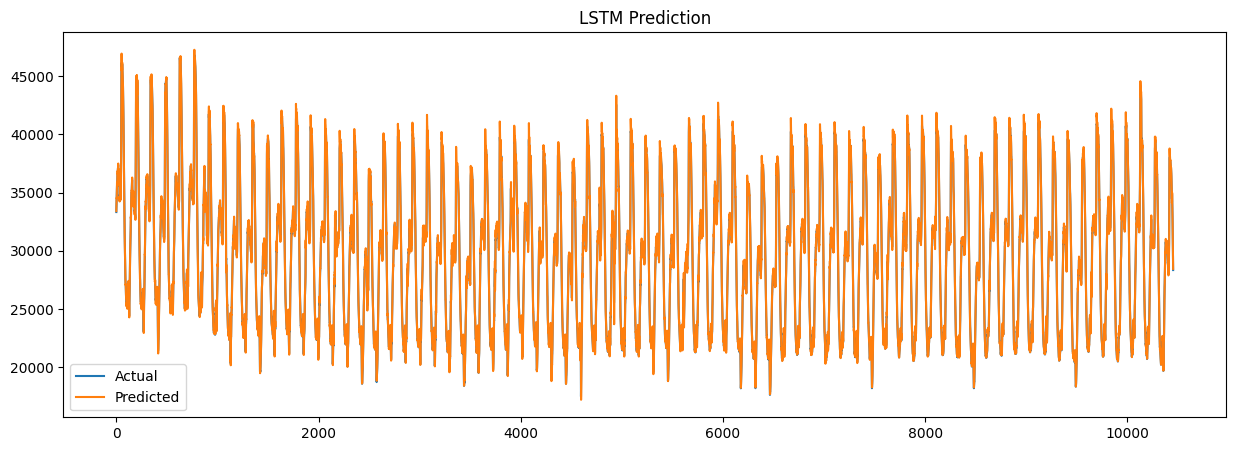

327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


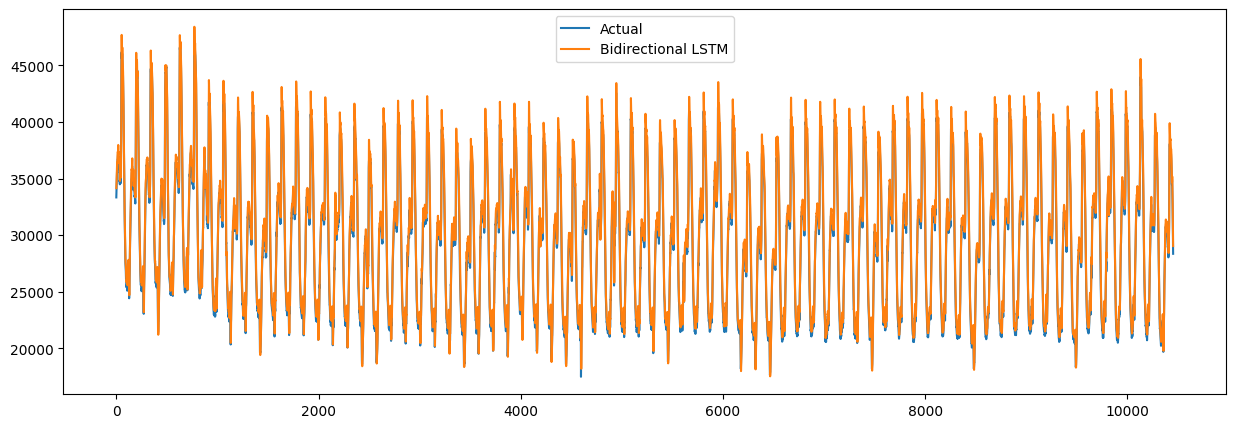

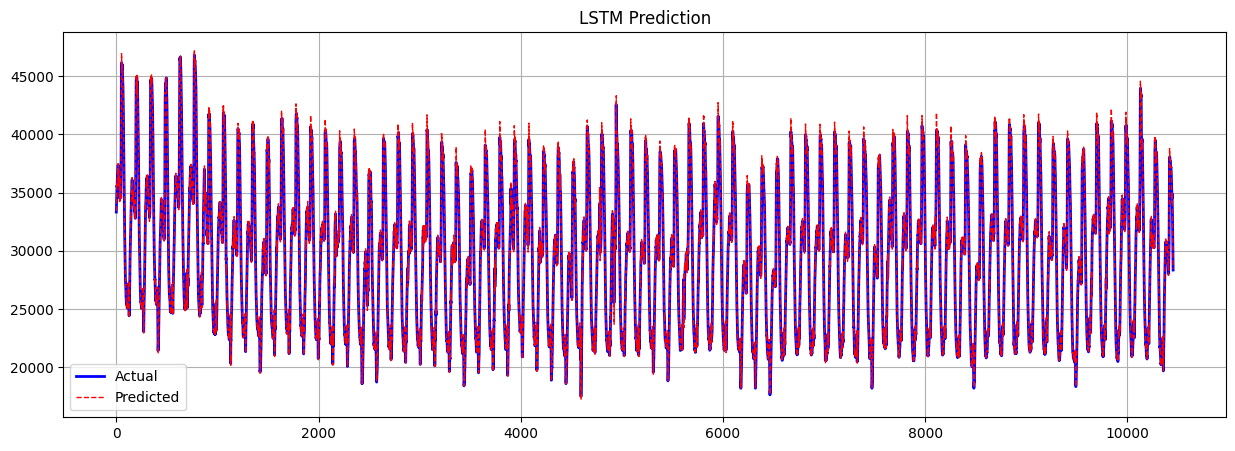

In [5]:
import zipfile
import matplotlib.pyplot as plt

zip_path = "powerconsumption.csv.zip"   # Change to your file name

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("D:\DL DATASET")

import os

for root, dirs, files in os.walk("D:\DL DATASET"):
    for file in files:
        print(file)

import pandas as pd

df = pd.read_csv("powerconsumption.csv")

print(df.head())
print(df.info())
print(df.columns)
print(df.isnull().sum())

df["Datetime"] = pd.to_datetime(df["Datetime"])

df = df.sort_values("Datetime")

df.head()

target = df[["PowerConsumption_Zone1"]]

target.head()

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(target)

train_size = int(len(scaled_data) * 0.8)

train = scaled_data[:train_size]
test = scaled_data[train_size:]

import numpy as np

def create_sequences(data, lookback):
    X = []
    y = []

    for i in range(len(data) - lookback):
        X.append(data[i:i+lookback])
        y.append(data[i+lookback])

    return np.array(X), np.array(y)

lookback = 30

X_train, y_train = create_sequences(train, lookback)
X_test, y_test = create_sequences(test, lookback)

print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

lstm_model = Sequential([

    LSTM(
        64,
        input_shape=(30,1)
    ),

    Dense(32, activation="relu"),

    Dense(1)

])

lstm_model.summary()

Model: "sequential_5"

lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        verbose=1
    )

]

history_lstm = lstm_model.fit(

    X_train,
    y_train,

    validation_data=(X_test,y_test),

    epochs=10,

    batch_size=32,

    callbacks=callbacks

)

loss_lstm, mae_lstm = lstm_model.evaluate(X_test, y_test, verbose=0)

print("LSTM Loss :", loss_lstm)
print("LSTM MAE  :", mae_lstm)

from tensorflow.keras.layers import Bidirectional, LSTM, Dense
from tensorflow.keras.models import Sequential

bilstm_model = Sequential([

    Bidirectional(
        LSTM(64),
        input_shape=(30,1)
    ),

    Dense(32, activation="relu"),

    Dense(1)

])

bilstm_model.summary()

Model: "sequential_6"

bilstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

history_bilstm = bilstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=10,
    batch_size=32,
    callbacks=callbacks
)

print(callbacks)

loss_bilstm, mae_bilstm = bilstm_model.evaluate(X_test, y_test, verbose=0)

print("Bidirectional LSTM Loss:", loss_bilstm)
print("Bidirectional LSTM MAE :", mae_bilstm)

comparison = pd.DataFrame({

    "Model":[
        "LSTM",
        "Bidirectional LSTM"
    ],

    "Loss":[
        loss_lstm,
        loss_bilstm
    ],

    "MAE":[
        mae_lstm,
        mae_bilstm
    ]

})

comparison

pred_lstm = lstm_model.predict(X_test)

pred_lstm = scaler.inverse_transform(pred_lstm)

actual = scaler.inverse_transform(y_test)

plt.figure(figsize=(15,5))

plt.plot(actual,label="Actual")

plt.plot(pred_lstm,label="Predicted")

plt.legend()

plt.title("LSTM Prediction")

plt.show()

pred_bilstm = bilstm_model.predict(X_test)

pred_bilstm = scaler.inverse_transform(pred_bilstm)

plt.figure(figsize=(15,5))

plt.plot(actual,label="Actual")

plt.plot(pred_bilstm,label="Bidirectional LSTM")

plt.legend()

plt.show()

plt.figure(figsize=(15,5))

plt.plot(actual, label="Actual", color="blue", linewidth=2)

plt.plot(pred_lstm,
         label="Predicted",
         color="red",
         linestyle="--",
         linewidth=1)

plt.legend()
plt.title("LSTM Prediction")
plt.grid(True)
plt.show()


Extraction Completed!
Commands/Classes found: ['go', 'stop', 'left', 'yes', 'right', 'down', 'no', 'up']
Number of classes: 8
Total Samples loaded: 800
X Shape: (800, 40)
y Shape: (800,)
x_train Shape: (640, 40, 1)
x_test Shape: (160, 40, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,240 (75.16 KB)

 Trainable params: 19,240 (75.16 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.1375 - loss: 2.1053 - val_accuracy: 0.1375 - val_loss: 2.0877
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1359 - loss: 2.0778 - val_accuracy: 0.1187 - val_loss: 2.0832
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1766 - loss: 2.0719 - val_accuracy: 0.1000 - val_loss: 2.0856
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1625 - loss: 2.0652 - val_accuracy: 0.0938 - val_loss: 2.0846
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1562 - loss: 2.0696 - val_accuracy: 0.1063 - val_loss: 2.0858
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1781 - loss: 2.0546 - val_accuracy: 0.1125 - val_loss: 2.0869
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1781 - loss: 2.0470 - val_accuracy: 0.1187 - val_loss: 2.0882
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.2094 - loss: 2.0414 - val_accuracy: 0.1125 - v

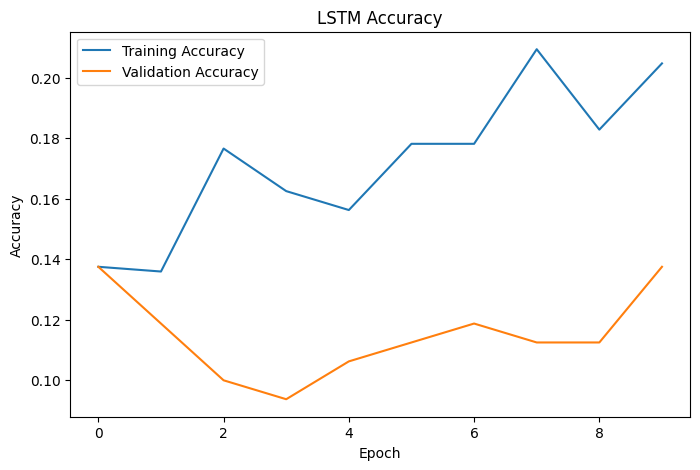

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step  


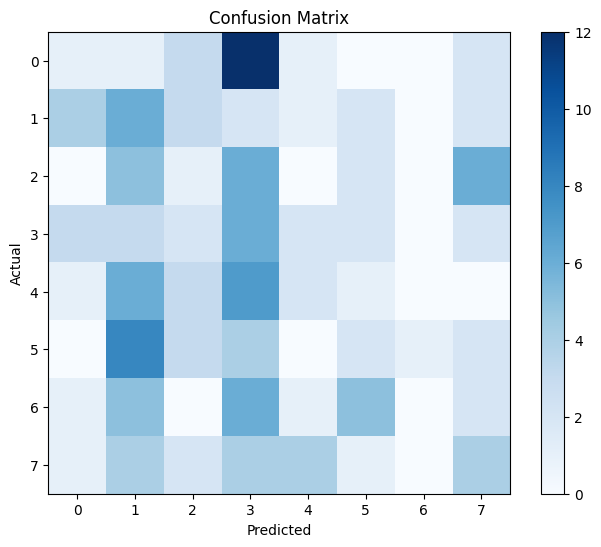

              precision    recall  f1-score   support

        down       0.09      0.05      0.06        20
          go       0.16      0.30      0.21        20
        left       0.06      0.05      0.05        20
          no       0.13      0.30      0.18        20
       right       0.18      0.10      0.13        20
        stop       0.13      0.10      0.11        20
          up       0.00      0.00      0.00        20
         yes       0.20      0.20      0.20        20

    accuracy                           0.14       160
   macro avg       0.12      0.14      0.12       160
weighted avg       0.12      0.14      0.12       160



In [10]:
import os
import zipfile
import random
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

# 1. Extraction
zip_path = "mini_speech_commands.zip"
extract_path = "mini_speech_commands"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction Completed!")

# 2. Set corrected dataset path to the nested folder containing audio
dataset_path = os.path.join("mini_speech_commands", "mini_speech_commands")

# Filter commands to ignore system directories like __MACOSX
commands = [
    d for d in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, d)) and not d.startswith("_")
]

print("Commands/Classes found:", commands)
print("Number of classes:", len(commands))

# Feature extraction helper
def extract_features(file_path):
    try:
        audio, sample_rate = librosa.load(file_path, sr=16000)
        mfcc = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
        mfcc = np.mean(mfcc.T, axis=0)
        return mfcc
    except Exception as e:
        print("Error reading:", file_path)
        return None

# 3. Load samples
features = []
random.seed(42)
samples_per_class = 100

for command in commands:
    folder = os.path.join(dataset_path, command)
    wav_files = [f for f in os.listdir(folder) if f.endswith(".wav")]
    random.shuffle(wav_files)
    wav_files = wav_files[:samples_per_class]

    for file in wav_files:
        path = os.path.join(folder, file)
        feature = extract_features(path)
        if feature is not None:
            features.append([feature, command])

print("Total Samples loaded:", len(features))

# Convert to dataframe
features_df = pd.DataFrame(features, columns=["feature", "label"])

X = np.array(features_df["feature"].tolist())
y = np.array(features_df["label"].tolist())

print("X Shape:", X.shape)
print("y Shape:", y.shape)

# Encode labels
encoder = LabelEncoder()
y = encoder.fit_transform(y)

# 4. Train-Test Split (fixed case-consistency to lowercase x)
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Reshape dataset for LSTM (Samples, Time Steps, Features)
x_train = x_train.reshape(x_train.shape[0], x_train.shape[1], 1)
x_test = x_test.reshape(x_test.shape[0], x_test.shape[1], 1)

print("x_train Shape:", x_train.shape)
print("x_test Shape:", x_test.shape)

# 5. Build and Train LSTM Model
lstm_model = Sequential([
    LSTM(64, input_shape=(40, 1)),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(len(encoder.classes_), activation="softmax")
])

lstm_model.summary()

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = lstm_model.fit(
    x_train,
    y_train,
    validation_data=(x_test, y_test),
    epochs=10,
    batch_size=32
)

# Evaluate Model
loss, accuracy = lstm_model.evaluate(x_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# Plot accuracy curves
plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Accuracy")
plt.legend()
plt.show()

# Confusion Matrix
y_pred = lstm_model.predict(x_test)
y_pred = y_pred.argmax(axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Classification Report
print(classification_report(
    y_test,
    y_pred,
    target_names=encoder.classes_
))